<a href="https://colab.research.google.com/github/danielkouame091-source/-25mda10119-brightmart-analytical-modelling-ml/blob/main/25MDA10119_Analytical-ModelingML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q datasets tensorflow

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

In [ ]:
print("Téléchargement du dataset...")
dataset = load_dataset("AliceRolan/CurrencyDataset")

print(dataset)
print("Exemple d'étiquettes :", dataset['train'].features['label'])

Téléchargement du dataset...


README.md:   0%|          | 0.00/635 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  130MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 61.0MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/500 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/196 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'label', 'documentType', 'category', 'filename', 'reason'],
        num_rows: 500
    })
    test: Dataset({
        features: ['image', 'label', 'documentType', 'category', 'filename', 'reason'],
        num_rows: 196
    })
})
Exemple d'étiquettes : ClassLabel(names=['Real', 'Fake'])


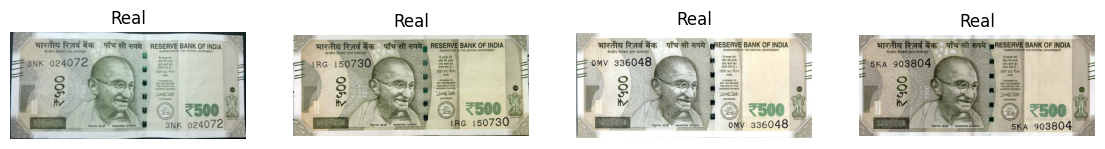

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for i, ax in enumerate(axes):
    img = dataset['train'][i]['image']
    label = dataset['train'][i]['label']
    label_name = dataset['train'].features['label'].int2str(label)
    ax.imshow(img)
    ax.set_title(label_name)
    ax.axis('off')
plt.show()

In [ ]:
IMG_SIZE = 128

def prepare_split(split):
    images = []
    labels = []
    for example in dataset[split]:
        img = example['image'].convert('RGB').resize((IMG_SIZE, IMG_SIZE))
        images.append(np.array(img) / 255.0)  # normalisation entre 0 et 1
        labels.append(example['label'])
    return np.array(images), np.array(labels)

X_train, y_train = prepare_split('train')
print(f"Images d'entraînement : {X_train.shape}")

# S'il n'y a pas de split 'test' dans le dataset, on en crée un nous-mêmes
if 'test' in dataset:
    X_test, y_test = prepare_split('test')
else:
    X_train, X_test, y_train, y_test = train_test_split(
        X_train, y_train, test_size=0.2, random_state=42, stratify=y_train
    )

print(f"Entraînement : {X_train.shape[0]} images | Test : {X_test.shape[0]} images")

Images d'entraînement : (500, 128, 128, 3)
Entraînement : 500 images | Test : 196 images


In [ ]:
cnn_model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(IMG_SIZE, IMG_SIZE, 3)),
    MaxPooling2D(2,2),
    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D(2,2),
    Conv2D(128, (3,3), activation='relu'),
    MaxPooling2D(2,2),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid')  # 0 = Real, 1 = Fake
])

cnn_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
cnn_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,769 (12.61 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = cnn_model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=15,
    batch_size=16
)

Epoch 1/15
32/32 ━━━━━━━━━━━━━━━━━━━━ 25s 716ms/step - accuracy: 0.5260 - loss: 0.6930 - val_accuracy: 0.6837 - val_loss: 0.6239
Epoch 2/15
32/32 ━━━━━━━━━━━━━━━━━━━━ 22s 681ms/step - accuracy: 0.6060 - loss: 0.6432 - val_accuracy: 0.7347 - val_loss: 0.5739
Epoch 3/15
32/32 ━━━━━━━━━━━━━━━━━━━━ 19s 598ms/step - accuracy: 0.6380 - loss: 0.6089 - val_accuracy: 0.7296 - val_loss: 0.5694
Epoch 4/15
32/32 ━━━━━━━━━━━━━━━━━━━━ 20s 621ms/step - accuracy: 0.6720 - loss: 0.5949 - val_accuracy: 0.6633 - val_loss: 0.5956
Epoch 5/15
32/32 ━━━━━━━━━━━━━━━━━━━━ 22s 674ms/step - accuracy: 0.6740 - loss: 0.5769 - val_accuracy: 0.6837 - val_loss: 0.5923
Epoch 6/15
32/32 ━━━━━━━━━━━━━━━━━━━━ 19s 595ms/step - accuracy: 0.6860 - loss: 0.5674 - val_accuracy: 0.6735 - val_loss: 0.5903
Epoch 7/15
32/32 ━━━━━━━━━━━━━━━━━━━━ 21s 649ms/step - accuracy: 0.6780 - loss: 0.5685 - val_accuracy: 0.7092 - val_loss: 0.5908
Epoch 8/15
32/32 ━━━━━━━━━━━━━━━━━━━━ 19s 591ms/step - accuracy: 0.6720 - loss: 0.5686 - val_accu

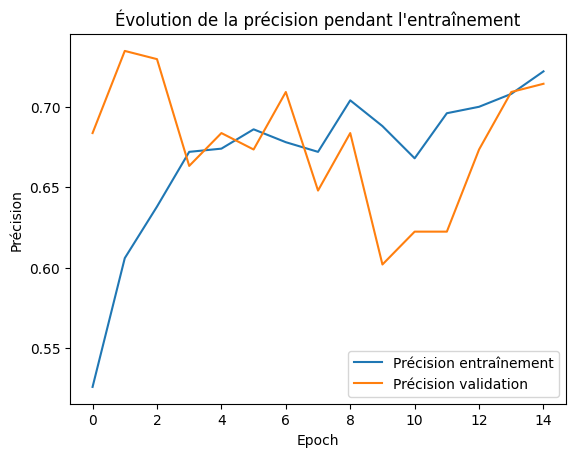

In [ ]:
plt.plot(history.history['accuracy'], label='Précision entraînement')
plt.plot(history.history['val_accuracy'], label='Précision validation')
plt.xlabel('Epoch')
plt.ylabel('Précision')
plt.legend()
plt.title("Évolution de la précision pendant l'entraînement")
plt.show()